Nạp cấu hình

In [1]:
import os, sys, json, re, subprocess
from pathlib import Path
import numpy as np
import pandas as pd

# Jupyter Lab chạy kernel với thư mục hiện hành = thư mục chứa notebook (ics-ai/notebooks)
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
# Phải trùng với WORK_DIR ở notebook 01
WORK_DIR = Path(os.environ.get('CIC_MODBUS_WORK', PROJECT_ROOT / 'Modbus-Work')).resolve()
CFG = json.loads((WORK_DIR / 'config.json').read_text(encoding='utf-8'))
DATA_ROOT = Path(CFG['data_root'])
SCENARIOS = list(CFG['capture_points'].keys())
ATTACK_SCENARIOS = [s for s in SCENARIOS if s != 'benign']
print('DATA_ROOT :', DATA_ROOT)
print('WORK_DIR  :', WORK_DIR)
print('Kịch bản  :', SCENARIOS)

import matplotlib.pyplot as plt
from tqdm.auto import tqdm
pd.set_option('display.max_colwidth', 80)
pd.set_option('display.width', 200)

def natural_key(p):
    return [int(t) if t.isdigit() else t.lower() for t in re.split(r'(\d+)', Path(p).name)]

DATA_ROOT : C:\Users\cvson\Documents\Project\Anomaly-detection-in-ICS\ics-ai\Modbus-Dataset
WORK_DIR  : C:\Users\cvson\Documents\Project\Anomaly-detection-in-ICS\ics-ai\Modbus-Work
Kịch bản  : ['benign', 'external', 'compromised_scada', 'compromised_ied']


Tham số gán nhãn

In [2]:
PAD_BEFORE_S = 0.05
PAD_AFTER_S  = 0.5
MERGE_GAP_S  = 60.0
UNCLOSED_DEFAULT_S = {
    'Brute force': 60.0, 'Query flooding': 5.0, 'Recon': 5.0, 'Replay': 5.0, 'FDI': 5.0,
    'Frame stacking': 1.0, 'Payload injection': 1.0, 'Length manipulation': 1.0, 'Delay response': 15.0,
}
REQUIRE_TARGET_IP = False

# Dò độ lệch thời gian log -> pcap
OFFSET_CANDIDATES_H = list(range(-14, 15))   # thử từ UTC-14 đến UTC+14 theo bước 1 giờ
OFFSET_SCORE_PAD_S  = 2.0                    # đệm rộng hơn khi chấm điểm độ lệch
MIN_SIGNATURE_HITS  = 5                      # ít hơn ngưỡng này thì dùng độ lệch chung của kịch bản
APPLY_FINE_OFFSET   = True                   # cộng thêm phần lệch lẻ (giây) nếu |lệch| > 0,25 s

CLASSES = ['Normal', 'Brute force', 'Query flooding', 'Replay', 'Frame stacking',
           'Payload injection', 'Recon', 'FDI', 'Length manipulation']        # thứ tự như Table 3
CLASS_ID = {c: i for i, c in enumerate(CLASSES)}
PAPER_COUNTS = {'Normal': 10_747_066, 'Brute force': 632_450, 'Frame stacking': 1_335, 'Query flooding': 5_967,
                'Recon': 355, 'Replay': 1_782, 'Payload injection': 363, 'Length manipulation': 26, 'FDI': 53}

Nạp các gói đã trích xuất

In [3]:
manifest = pd.read_csv(WORK_DIR / 'manifest.csv')
NEED = ['time', 'ip_src', 'ip_dst', 'func_code', 'n_pdus', 'mb_len', 'byte_cnt']
parts = []
for r in tqdm(manifest.itertuples(), total=len(manifest), desc='Nạp parquet'):
    f = WORK_DIR / 'extracted' / r.scenario / (Path(r.file).stem + '.parquet')
    d = pd.read_parquet(f, columns=NEED)
    if not len(d):
        continue
    d['ip_src'] = d['ip_src'].astype(str); d['ip_dst'] = d['ip_dst'].astype(str)
    d['scenario'] = r.scenario
    d['file_id'] = r.file_id
    d['row'] = np.arange(len(d), dtype=np.int32)
    parts.append(d)
P = pd.concat(parts, ignore_index=True)
for c in ['scenario', 'file_id', 'ip_src', 'ip_dst']:
    P[c] = P[c].astype('category')
del parts
print(f'{len(P):,} gói Modbus')
P.groupby('scenario', observed=True).agg(n=('time', 'size'),
    start=('time', lambda s: pd.to_datetime(s.min(), unit='s')),
    end=('time', lambda s: pd.to_datetime(s.max(), unit='s')))

Nạp parquet:   0%|          | 0/58 [00:00<?, ?it/s]

11,390,143 gói Modbus


,n,start,end
scenario,,,
benign,4101460,2023-01-23 13:52:04.004200935,2023-01-31 16:25:58.037503958
compromised_ied,3348713,2023-03-23 02:31:40.940954924,2023-03-29 16:15:45.449326038
compromised_scada,3657891,2023-03-15 02:01:08.009526014,2023-03-22 03:55:20.413600922
external,282079,2023-02-01 03:48:39.921816111,2023-02-01 14:01:50.737515926


Đọc và chuẩn hóa attack log

In [4]:
ATTACK_PATTERNS = [            # (type, regex) — xét theo thứ tự, khớp đầu tiên thắng
    ('Delay response',      r'delay'),
    ('FDI',                 r'false data injection'),
    ('Frame stacking',      r'stack'),
    ('Brute force',         r'brute force'),
    ('Length manipulation', r'length manipulation'),
    ('Payload injection',   r'payload injection'),
    ('Replay',              r'replay'),
    ('Recon',               r'^recon'),
    ('Query flooding',      r'query flood'),
]
END_REGEX = r'complete|sending response'
MMSS_REGEX = r'^\d{1,2}:\d{2}(\.\d+)?$'      # timestamp hỏng kiểu "07:40.5"

def classify(msg: str):
    m = msg.strip().lower()
    for typ, rx in ATTACK_PATTERNS:
        if re.search(rx, m):
            return typ, ('end' if re.search(END_REGEX, m) else 'start')
    return None, None

def date_from_path(path: Path):
    for part in [path.stem] + [p.name for p in path.parents]:
        m = re.search(r'(\d{2})-(\d{2})-(\d{4})', part)
        if m:
            return pd.Timestamp(f'{m.group(3)}-{m.group(1)}-{m.group(2)}')
    return None

def repair_mmss(ts_raw: pd.Series, day: pd.Timestamp) -> pd.Series:
    """'MM:SS.s' -> datetime. Giờ được suy ra theo thứ tự dòng: mỗi lần MM:SS 'quay vòng' thì +1 giờ.
    Phần giờ tuyệt đối (giờ bắt đầu) không biết được -> để bước dò độ lệch theo giờ (mục 5) sửa."""
    secs = ts_raw.str.split(':').map(lambda x: int(x[0]) * 60 + float(x[1])).to_numpy()
    hour, prev, out = 0, None, []
    for s in secs:
        if prev is not None and s < prev - 1800:
            hour += 1
        out.append(day + pd.Timedelta(hours=hour, seconds=s))
        prev = s
    return pd.Series(out, index=ts_raw.index)

def read_log(path: Path, scen: str) -> pd.DataFrame:
    df = pd.read_csv(path, dtype=str, keep_default_na=False)
    df.columns = [c.strip() for c in df.columns]
    ts_raw = df['Timestamp'].str.strip()
    repaired = ts_raw.str.match(MMSS_REGEX).mean() > 0.5
    if repaired:
        ts = repair_mmss(ts_raw, date_from_path(path))
    else:
        ts = pd.to_datetime(ts_raw, errors='coerce', format='mixed')
    tc = df['Attack'].map(classify)
    out = pd.DataFrame({
        'scenario': scen, 'log_file': path.relative_to(DATA_ROOT).as_posix(), 'ts_local': ts,
        'msg': df['Attack'].str.strip(), 'type': tc.str[0], 'kind': tc.str[1],
        'target_ip': df['TargetIP'].str.strip() if 'TargetIP' in df else '',
        'ts_repaired': repaired})
    return out

logs = []
for scen, rel in CFG['log_dirs'].items():
    for f in sorted((DATA_ROOT / rel).rglob('*.csv'), key=lambda p: str(p)):
        logs.append(read_log(f, scen))
E = pd.concat(logs, ignore_index=True)
E['t_log'] = (E['ts_local'] - pd.Timestamp('1970-01-01')).dt.total_seconds()
print(f'{len(E):,} dòng log từ {E.log_file.nunique()} file')

bad_ts = E[E.ts_local.isna()]
if len(bad_ts):
    print(f'⚠ {len(bad_ts)} dòng không đọc được thời gian -> bỏ qua'); E = E[E.ts_local.notna()]
rep = E[E.ts_repaired].log_file.unique()
if len(rep):
    print('⚠ Log có timestamp hỏng (MM:SS.s) đã được khôi phục giờ:', list(rep))

unk = E[E.type.isna()].msg.str.replace(r'\d+', 'N', regex=True).value_counts()
print('\nThông điệp không nhận dạng được (phải rỗng):'); print(unk if len(unk) else '  (không có)')
E = E[E.type.notna()].copy()
E.groupby(['scenario', 'type', 'kind']).size().unstack('kind', fill_value=0)

1,420,042 dòng log từ 34 file
⚠ Log có timestamp hỏng (MM:SS.s) đã được khôi phục giờ: ['attack/compromised-scada/attack logs/03-21-2023/03-21-2023-1-original.csv', 'attack/compromised-ied/attack logs/03-23-2023/03-23-2023-1.csv']

Thông điệp không nhận dạng được (phải rỗng):
  (không có)


kind                                      end   start
scenario          type                               
compromised_ied   Delay response           50      50
                  FDI                       0      54
                  Frame stacking           58      58
                  Length manipulation      71      71
                  Payload injection        45      45
                  Query flooding           28      63
                  Replay                    0      83
compromised_scada Brute force          639759  639759
                  Frame stacking          712     712
                  Length manipulation     656     656
                  Payload injection       664     664
                  Query flooding          671     704
                  Recon                   661     661
                  Replay                  940     940
external          Brute force           65556   65559
                  Frame stacking            1       1
                  Length manipulation       1       1
                  Payload injection         1       1
                  Query flooding            1       8
                  Recon                    32      43
                  Replay                    1       1

Dựng cửa sổ tấn công và dò độ lệch thời gian

In [5]:
def build_windows(ev: pd.DataFrame, offset_s: float = 0.0) -> pd.DataFrame:
    """ev: sự kiện của MỘT file log. Trả về cửa sổ (chưa đệm, chưa gộp) theo giờ pcap."""
    ev = ev.sort_values('t_log', kind='stable')
    all_t = np.unique(ev.t_log.to_numpy())
    rows = []
    for (typ, tgt), g in ev.groupby(['type', 'target_ip'], sort=False):
        open_t = None
        def close_unclosed(t0):
            nxt_i = np.searchsorted(all_t, t0, side='right')
            nxt = all_t[nxt_i] if nxt_i < len(all_t) else np.inf
            end = min(t0 + UNCLOSED_DEFAULT_S[typ], nxt)
            rows.append((typ, tgt, t0, end, 'unclosed_capped' if end < t0 + UNCLOSED_DEFAULT_S[typ] else 'unclosed'))
        for t, k in zip(g.t_log.to_numpy(), g.kind.to_numpy()):
            if k == 'start':
                if open_t is not None:
                    close_unclosed(open_t)
                open_t = t
            else:
                if open_t is not None:
                    rows.append((typ, tgt, open_t, t, 'closed')); open_t = None
                else:
                    rows.append((typ, tgt, t, t, 'end_only'))
        if open_t is not None:
            close_unclosed(open_t)
    w = pd.DataFrame(rows, columns=['type', 'target_ip', 'start', 'end', 'how'])
    w['start'] += offset_s; w['end'] += offset_s
    return w

def merge_windows(w: pd.DataFrame, gap: float, by=('scenario', 'type', 'target_ip')) -> pd.DataFrame:
    out = []
    for key, g in w.sort_values('start').groupby(list(by), sort=False):
        s, e, n, hows = None, None, 0, set()
        for r in g.itertuples():
            if s is None:
                s, e, n, hows = r.start, r.end, 1, {r.how}
            elif r.start - e <= gap:
                e, n = max(e, r.end), n + 1; hows.add(r.how)
            else:
                out.append((*key, s, e, n, '+'.join(sorted(hows)))); s, e, n, hows = r.start, r.end, 1, {r.how}
        if s is not None:
            out.append((*key, s, e, n, '+'.join(sorted(hows))))
    return pd.DataFrame(out, columns=list(by) + ['start', 'end', 'n_events', 'how'])

def in_windows(t: np.ndarray, starts: np.ndarray, ends: np.ndarray) -> np.ndarray:
    """Mask t nằm trong hợp các khoảng [starts, ends] (đã gộp, không chồng nhau, đã sắp xếp)."""
    if len(starts) == 0:
        return np.zeros(len(t), bool)
    idx = np.searchsorted(starts, t, side='right') - 1
    ok = idx >= 0
    ok[ok] = t[ok] <= ends[idx[ok]]
    return ok

def union(starts, ends):
    """Gộp các khoảng có thể chồng nhau -> (starts, ends) không chồng nhau."""
    if len(starts) == 0:
        return np.array([]), np.array([])
    o = np.argsort(starts); s, e = np.asarray(starts)[o], np.asarray(ends)[o]
    S, Ee = [s[0]], [e[0]]
    for a, b in zip(s[1:], e[1:]):
        if a <= Ee[-1]:
            Ee[-1] = max(Ee[-1], b)
        else:
            S.append(a); Ee.append(b)
    return np.array(S), np.array(Ee)

SIGNATURES = {   # type -> hàm chọn gói chữ ký
    'Brute force':    lambda d: d.func_code.to_numpy() == 5,
    'Frame stacking': lambda d: d.n_pdus.to_numpy() > 1,
    'FDI':            lambda d: d.byte_cnt.to_numpy() == 171,
}
sig_times = {}
for scen in ATTACK_SCENARIOS:
    d = P[P.scenario == scen]
    sig_times[scen] = {typ: np.sort(d.time.to_numpy()[f(d)]) for typ, f in SIGNATURES.items()}
    print(scen, {k: len(v) for k, v in sig_times[scen].items()})

external {'Brute force': 65804, 'Frame stacking': 1, 'FDI': 0}
compromised_scada {'Brute force': 718317, 'Frame stacking': 1318, 'FDI': 0}
compromised_ied {'Brute force': 3226, 'Frame stacking': 127, 'FDI': 53}


In [6]:
def score_offset(w0, scen, offset_s):
    """w0: cửa sổ của một file log dựng với độ lệch 0 (cửa sổ chỉ dịch chuyển theo độ lệch)."""
    hits = 0
    for typ, ts in sig_times[scen].items():
        ww = w0[w0.type == typ]
        if len(ww) == 0 or len(ts) == 0:
            continue
        s, e = union(ww.start.to_numpy() + offset_s - OFFSET_SCORE_PAD_S, ww.end.to_numpy() + offset_s + OFFSET_SCORE_PAD_S)
        hits += int(in_windows(ts, s, e).sum())
    return hits

def burst_starts(starts, ends, gap=MERGE_GAP_S):
    """Thời điểm bắt đầu của từng 'đợt' (các cửa sổ cách nhau < gap được coi là một đợt)."""
    if len(starts) == 0:
        return np.array([])
    o = np.argsort(starts); s, e = np.asarray(starts)[o], np.asarray(ends)[o]
    out, cur_end = [s[0]], e[0]
    for a, b in zip(s[1:], e[1:]):
        if a > cur_end + gap:
            out.append(a)
        cur_end = max(cur_end, b)
    return np.array(out)

def fine_residual(w0, scen, offset_s):
    """Độ lệch lẻ = trung vị (gói chữ ký đầu tiên của mỗi đợt tấn công − thời điểm bắt đầu đợt đó)."""
    deltas = []
    for typ, ts in sig_times[scen].items():
        ww = w0[w0.type == typ]
        if len(ts) == 0 or len(ww) == 0:
            continue
        st = burst_starts(ww.start.to_numpy() + offset_s, ww.end.to_numpy() + offset_s)
        i = np.searchsorted(ts, st - OFFSET_SCORE_PAD_S)
        ok = i < len(ts)
        d = ts[i[ok]] - st[ok]
        deltas.extend(d[np.abs(d) <= OFFSET_SCORE_PAD_S].tolist())
    return (float(np.median(deltas)), len(deltas)) if deltas else (0.0, 0)

W0 = {lf: build_windows(ev, 0.0) for lf, ev in E.groupby('log_file', sort=False)}
off_rows, pooled = [], {}
for (scen, lf), ev in tqdm(E.groupby(['scenario', 'log_file'], sort=False), desc='Dò độ lệch'):
    scores = {h: score_offset(W0[lf], scen, h * 3600) for h in OFFSET_CANDIDATES_H}
    for h, v in scores.items():
        pooled.setdefault(scen, {}).setdefault(h, 0)
        pooled[scen][h] += v
    best_h = max(scores, key=lambda h: (scores[h], -abs(h)))
    off_rows.append(dict(scenario=scen, log_file=lf, best_hour=best_h, hits=scores[best_h],
                         hits_at_0h=scores.get(0, 0), repaired=bool(ev.ts_repaired.iloc[0]),
                         log_start=ev.ts_local.min(), log_end=ev.ts_local.max(), n_events=len(ev)))
OFF = pd.DataFrame(off_rows)

# Độ lệch chung của kịch bản = điểm cộng dồn của mọi file log trong kịch bản.
# File log có quá ít gói chữ ký (< MIN_SIGNATURE_HITS) sẽ dùng độ lệch chung này.
SCEN_OFFSET_H = {}
for scen, sc in pooled.items():
    h = max(sc, key=lambda h: (sc[h], -abs(h)))
    SCEN_OFFSET_H[scen] = h
    print(f'{scen:18s} độ lệch chung = {h:+d} giờ  (số gói chữ ký khớp: {sc[h]}, nếu dùng 0 giờ: {sc.get(0, 0)})')
    if sc[h] == 0:
        print(f'  ⚠ Không có gói chữ ký nào khớp cho {scen}: không xác định được độ lệch, tạm dùng 0. '
              'Kiểm tra khoảng thời gian pcap và log!')
weak = OFF.hits < MIN_SIGNATURE_HITS
OFF.loc[weak, 'best_hour'] = OFF.loc[weak, 'scenario'].map(SCEN_OFFSET_H)
OFF['source'] = np.where(weak, 'scenario_pooled', 'signature')

fine = []
for r in OFF.itertuples():
    res, n = fine_residual(W0[r.log_file], r.scenario, r.best_hour * 3600)
    fine.append((res, n))
OFF['fine_residual_s'] = [round(x[0], 3) for x in fine]
OFF['fine_n'] = [x[1] for x in fine]
OFF['offset_s'] = OFF.best_hour * 3600 + np.where(
    APPLY_FINE_OFFSET & (OFF.fine_residual_s.abs() > 0.25) & (OFF.fine_n >= MIN_SIGNATURE_HITS),
    OFF.fine_residual_s, 0.0)
OFF.to_csv(WORK_DIR / 'log_offsets.csv', index=False)

nonrep = OFF[~OFF.repaired & (OFF.source == 'signature')]
for scen, g in nonrep.groupby('scenario'):
    if g.best_hour.nunique() > 1:
        print(f'⚠ {scen}: các file log cho độ lệch khác nhau {sorted(g.best_hour.unique())} giờ — hãy xem lại.')
OFF[['scenario', 'log_file', 'n_events', 'repaired', 'best_hour', 'hits', 'hits_at_0h', 'source',
     'fine_residual_s', 'fine_n', 'offset_s']]

Dò độ lệch:   0%|          | 0/34 [00:00<?, ?it/s]

external           độ lệch chung = +0 giờ  (số gói chữ ký khớp: 65560, nếu dùng 0 giờ: 65560)
compromised_scada  độ lệch chung = +0 giờ  (số gói chữ ký khớp: 617405, nếu dùng 0 giờ: 617405)
compromised_ied    độ lệch chung = +0 giờ  (số gói chữ ký khớp: 107, nếu dùng 0 giờ: 107)
⚠ compromised_scada: các file log cho độ lệch khác nhau [np.int64(0), np.int64(9), np.int64(14)] giờ — hãy xem lại.


,scenario,log_file,n_events,repaired,best_hour,hits,hits_at_0h,source,fine_residual_s,fine_n,offset_s
0,external,attack/external/external-attacker/attacker logs/01-01-2023/01-01-2023-1.csv,1,False,0,0,0,scenario_pooled,0.000,0,0.0
1,external,attack/external/external-attacker/attacker logs/01-02-2023/01-02-2023-1.csv,2,False,0,0,0,scenario_pooled,0.000,0,0.0
2,external,attack/external/external-attacker/attacker logs/01-17-2023/01-17-2023-1.csv,6,False,0,0,0,scenario_pooled,0.000,0,0.0
3,external,attack/external/external-attacker/attacker logs/02-01-2023/02-01-2023-1.csv,131187,False,0,65560,65560,signature,0.001,2,0.0
4,external,attack/external/external-attacker/attacker logs/12-29-2022/12-29-2022-1.csv,1,False,0,0,0,scenario_pooled,0.000,0,0.0
5,external,attack/external/external-attacker/attacker logs/12-30-2022/12-30-2022-1.csv,10,False,0,0,0,scenario_pooled,0.000,0,0.0
6,compromised_scada,attack/compromised-scada/attack logs/03-12-2023/03-12-2023-1.csv,107770,False,0,0,0,scenario_pooled,0.000,0,0.0
7,compromised_scada,attack/compromised-scada/attack logs/03-12-2023/03-12-2023-2.csv,33566,False,0,0,0,scenario_pooled,0.000,0,0.0
8,compromised_scada,attack/compromised-scada/attack logs/03-12-2023/03-12-2023-3.csv,41618,False,0,0,0,scenario_pooled,0.000,0,0.0
9,compromised_scada,attack/compromised-scada/attack logs/03-13-2023/03-13-2023-1.csv,106092,False,0,0,0,scenario_pooled,0.000,0,0.0


Dựng cửa sổ chính thức với độ lệch đã chọn

In [7]:
W_raw = []
for r in OFF.itertuples():
    w = W0[r.log_file].copy()
    w['start'] += r.offset_s; w['end'] += r.offset_s
    w['scenario'] = r.scenario; w['log_file'] = r.log_file
    W_raw.append(w)
W_raw = pd.concat(W_raw, ignore_index=True)
if not REQUIRE_TARGET_IP:
    W_raw['target_ip'] = ''
W = merge_windows(W_raw, MERGE_GAP_S)
W['duration_s'] = (W.end - W.start).round(3)
W['start_utc'] = pd.to_datetime(W.start, unit='s')

# Cửa sổ có nằm trong khoảng thời gian pcap không?
cov = P.groupby('file_id', observed=True).time.agg(['min', 'max']).reset_index()
cov['scenario'] = cov.file_id.astype(str).str.split('/').str[0]
def covered(r):
    c = cov[cov.scenario == r.scenario]
    return bool(((c['min'] <= r.end) & (c['max'] >= r.start)).any())
W['in_pcap_coverage'] = W.apply(covered, axis=1)
W.to_csv(WORK_DIR / 'attack_windows.csv', index=False)

summary_w = W.groupby(['scenario', 'type']).agg(n_windows=('start', 'size'),
        in_coverage=('in_pcap_coverage', 'sum'), median_dur_s=('duration_s', 'median'),
        how=('how', lambda s: ', '.join(sorted(set('+'.join(s).split('+'))))))
summary_w

n_windows  in_coverage  median_dur_s                                how
scenario          type                                                                                        
compromised_ied   Delay response              50           50        7.1890                             closed
                  FDI                         54           54        5.0000                           unclosed
                  Frame stacking              58           58        0.0010                             closed
                  Length manipulation         71           71        0.0000                             closed
                  Payload injection           45           45        0.0010                             closed
                  Query flooding              63           63        5.0000                   closed, unclosed
                  Replay                      83           76        5.0000                           unclosed
compromised_scada Brute force                324          220        0.0505                             closed
                  Frame stacking             177          125        0.0090                             closed
                  Length manipulation        163          113        0.0090                             closed
                  Payload injection          163          119        0.0080                             closed
                  Query flooding             173          129        0.0130  closed, unclosed, unclosed_capped
                  Recon                      164          110        0.0105                             closed
                  Replay                     183          123        0.0020                             closed
external          Brute force                  5            2       60.0000  closed, unclosed, unclosed_capped
                  Frame stacking               1            1        0.0030                             closed
                  Length manipulation          1            1        0.0020                             closed
                  Payload injection            1            1        0.0010                             closed
                  Query flooding               8            2        5.0000                   closed, unclosed
                  Recon                       37           27        0.0010                   closed, unclosed
                  Replay                       1            1        0.0000                             closed

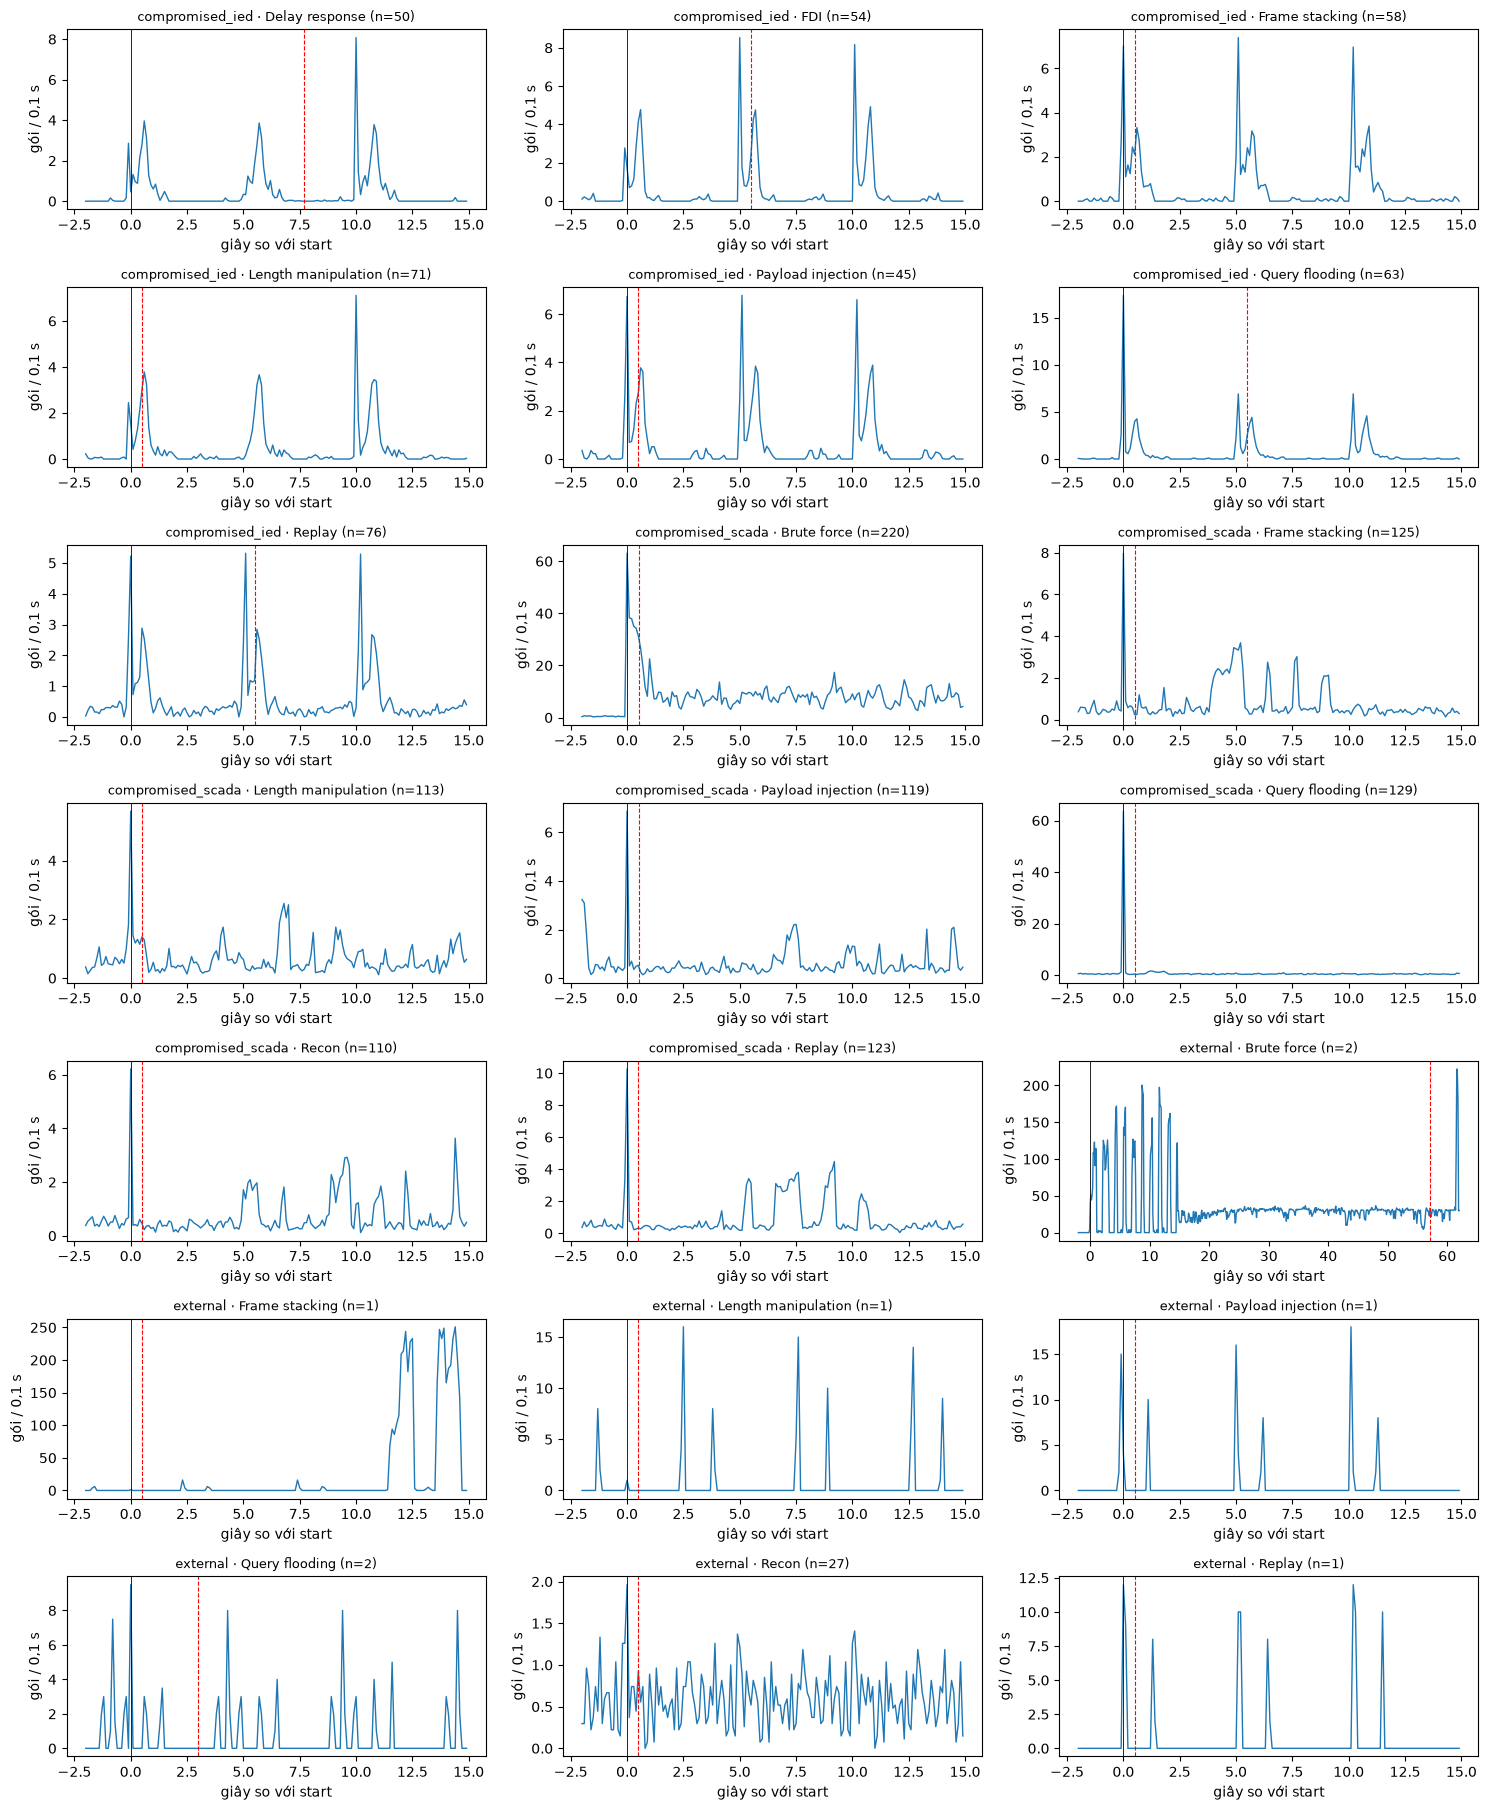

In [8]:
pairs = W[W.in_pcap_coverage].groupby(['scenario', 'type']).size().index.tolist()
if pairs:
    ncol = 3; nrow = int(np.ceil(len(pairs) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(5 * ncol, 2.6 * nrow), squeeze=False)
    for ax, (scen, typ) in zip(axes.flat, pairs):
        t = np.sort(P.time.to_numpy()[(P.scenario == scen).to_numpy()])
        ww = W[(W.scenario == scen) & (W.type == typ) & W.in_pcap_coverage].head(300)
        right = float(min(120.0, max(15.0, ww.duration_s.median() + PAD_AFTER_S + 5)))
        BINS = np.linspace(-2.0, right, int((right + 2.0) / 0.1) + 1)
        hist = np.zeros(len(BINS) - 1)
        for st in ww.start.to_numpy():
            lo, hi = np.searchsorted(t, [st + BINS[0], st + BINS[-1]])
            hist += np.histogram(t[lo:hi] - st, BINS)[0]
        ax.plot(BINS[:-1], hist / max(len(ww), 1), lw=1)
        ax.axvline(0, color='k', lw=0.6)
        ax.axvline(ww.duration_s.median() + PAD_AFTER_S, color='r', ls='--', lw=0.8)
        ax.set_title(f'{scen} · {typ} (n={len(ww)})', fontsize=9)
        ax.set_xlabel('giây so với start'); ax.set_ylabel('gói / 0,1 s')
    for ax in list(axes.flat)[len(pairs):]:
        ax.axis('off')
    plt.tight_layout(); plt.show()
else:
    print('Không có cửa sổ nào nằm trong vùng pcap — kiểm tra lại Mục 5.')

Gán nhãn

In [9]:
def fc_len_code(d):
    return (d.func_code.to_numpy().astype(np.int64) + 1) * 100_000 + (d.mb_len.to_numpy().astype(np.int64) + 1)

benign = P[P.scenario == 'benign']
BENIGN_CODES = np.unique(fc_len_code(benign))
assert len(BENIGN_CODES), 'Không có dữ liệu benign để làm tham chiếu cho luật length manipulation'
ex = sorted((int(c // 100_000) - 1, int(c % 100_000) - 1) for c in BENIGN_CODES)
print(f'{len(BENIGN_CODES)} cặp (func_code, mb_len) hợp lệ từ benign, ví dụ:', ex[:10])

WINDOW_RULES = ['Brute force', 'Length manipulation', 'Payload injection', 'Replay', 'Recon', 'Query flooding']

def window_mask(d: pd.DataFrame, ww: pd.DataFrame, pad_b: float, pad_a: float) -> np.ndarray:
    t = d.time.to_numpy()
    mask = np.zeros(len(d), bool)
    for tgt, g in ww.groupby('target_ip'):
        s, e = union(g.start.to_numpy() - pad_b, g.end.to_numpy() + pad_a)
        m = in_windows(t, s, e)
        if REQUIRE_TARGET_IP and tgt:
            m &= (d.ip_src.astype(str).to_numpy() == tgt) | (d.ip_dst.astype(str).to_numpy() == tgt)
        mask |= m
    return mask

def apply_rules(P: pd.DataFrame, W: pd.DataFrame, pad_b=PAD_BEFORE_S, pad_a=PAD_AFTER_S):
    label = np.zeros(len(P), np.int8)                 # 0 = Normal
    delay = np.zeros(len(P), bool)
    for scen in ATTACK_SCENARIOS:
        idx = np.flatnonzero((P.scenario == scen).to_numpy())
        if not len(idx):
            continue
        d = P.iloc[idx]
        lab = np.zeros(len(d), np.int8)
        def assign(mask, cls):
            m = mask & (lab == 0); lab[m] = CLASS_ID[cls]
        fc = d.func_code.to_numpy()
        ws = {typ: W[(W.scenario == scen) & (W.type == typ)] for typ in W.type.unique()}
        empty = W.iloc[:0]
        assign(d.byte_cnt.to_numpy() == 171, 'FDI')
        assign(d.n_pdus.to_numpy() > 1, 'Frame stacking')
        assign(window_mask(d, ws.get('Brute force', empty), pad_b, pad_a) & (fc == 5), 'Brute force')
        anomalous = ~np.isin(fc_len_code(d), BENIGN_CODES)
        assign(window_mask(d, ws.get('Length manipulation', empty), pad_b, pad_a) & anomalous, 'Length manipulation')
        for typ in ['Payload injection', 'Replay', 'Recon', 'Query flooding']:
            assign(window_mask(d, ws.get(typ, empty), pad_b, pad_a), typ)
        label[idx] = lab
        delay[idx] = window_mask(d, ws.get('Delay response', empty), pad_b, pad_a)
    return label, delay

label, in_delay = apply_rules(P, W)
P['label_id'] = label
P['label'] = pd.Categorical.from_codes(label, CLASSES)
P['in_delay_window'] = in_delay
print('Xong. Số gói bị đánh dấu in_delay_window:', int(in_delay.sum()))

10 cặp (func_code, mb_len) hợp lệ từ benign, ví dụ: [(1, 4), (1, 6), (2, 4), (2, 6), (3, 5), (3, 6), (4, 5), (4, 6), (5, 6), (6, 6)]
Xong. Số gói bị đánh dấu in_delay_window: 2200


Kết quả và đối chiếu với bài báo

In [10]:
cnt = P.groupby(['label', 'scenario'], observed=False).size().unstack('scenario', fill_value=0)
cnt = cnt[[s for s in SCENARIOS if s in cnt.columns]]
cnt['total'] = cnt.sum(axis=1)
cnt['paper'] = cnt.index.map(PAPER_COUNTS)
cnt['% of total'] = (100 * cnt.total / cnt.total.sum()).round(3)
print(f"Normal: {int(cnt.loc['Normal', 'total']):,}  |  Attack: {int(cnt.total.sum() - cnt.loc['Normal', 'total']):,}"
      f"   (bài báo: 10,747,066 | 642,331)")
cnt.to_csv(WORK_DIR / 'label_summary.csv')
cnt

Normal: 10,690,745  |  Attack: 699,398   (bài báo: 10,747,066 | 642,331)


scenario,benign,external,compromised_scada,compromised_ied,total,paper,% of total
label,,,,,,,
Normal,4101460,215349,3031648,3342288,10690745,10747066,93.860
Brute force,0,65558,612008,0,677566,632450,5.949
Query flooding,0,48,8401,2471,10920,5967,0.096
Replay,0,21,1624,3073,4718,1782,0.041
Frame stacking,0,1,1318,127,1446,1335,0.013
Payload injection,0,11,1541,635,2187,363,0.019
Recon,0,1090,911,0,2001,355,0.018
FDI,0,0,0,53,53,53,0.000
Length manipulation,0,1,440,66,507,26,0.004


Hiệu quả của từng cửa sổ

In [11]:
rows = []
per_scen = {}
for scen in ATTACK_SCENARIOS:
    d = P[P.scenario == scen]
    o = np.argsort(d.time.to_numpy(), kind='stable')
    per_scen[scen] = (d.time.to_numpy()[o], d.label.astype(str).to_numpy()[o])
for r in W[W.in_pcap_coverage & (W.type != 'Delay response')].itertuples():
    t, lab = per_scen[r.scenario]
    lo, hi = np.searchsorted(t, [r.start - PAD_BEFORE_S, r.end + PAD_AFTER_S], side='left')
    hi = np.searchsorted(t, r.end + PAD_AFTER_S, side='right')
    rows.append((r.scenario, r.type, int(hi - lo), int((lab[lo:hi] == r.type).sum())))
eff = pd.DataFrame(rows, columns=['scenario', 'type', 'pkts_in_window', 'labelled_as_type'])
eff.groupby(['scenario', 'type']).agg(windows=('type', 'size'),
    windows_with_label=('labelled_as_type', lambda s: int((s > 0).sum())),
    hit_rate=('labelled_as_type', lambda s: round((s > 0).mean(), 3)),
    pkts_in_windows=('pkts_in_window', 'sum'), labelled=('labelled_as_type', 'sum'))

windows  windows_with_label  hit_rate  pkts_in_windows  labelled
scenario          type                                                                                 
compromised_ied   FDI                       54                  51     0.944             2018        51
                  Frame stacking            58                  56     0.966              933        56
                  Length manipulation       71                  66     0.930              615        66
                  Payload injection         45                  42     0.933              635       635
                  Query flooding            63                  62     0.984             2537      2471
                  Replay                    76                  76     1.000             3073      3073
compromised_scada Brute force              220                 212     0.964           631937    612008
                  Frame stacking           125                 121     0.968             1363       566
                  Length manipulation      113                 110     0.973             3936       440
                  Payload injection        119                 115     0.966             1563      1541
                  Query flooding           129                 121     0.938             9059      8401
                  Recon                    110                 106     0.964              911       911
                  Replay                   123                 120     0.976             2315      1624
external          Brute force                2                   2     1.000            66238     65558
                  Frame stacking             1                   0     0.000                1         0
                  Length manipulation        1                   1     1.000                1         1
                  Payload injection          1                   1     1.000               11        11
                  Query flooding             2                   2     1.000               49        48
                  Recon                     27                  27     1.000             1090      1090
                  Replay                     1                   1     1.000               21        21

In [12]:
rows = []
CHECKS = [('FDI (byte_cnt=171)', 'FDI', lambda d: d.byte_cnt.to_numpy() == 171),
          ('Frame stacking (n_pdus>1)', 'Frame stacking', lambda d: d.n_pdus.to_numpy() > 1),
          ('FC=5', 'Brute force', lambda d: d.func_code.to_numpy() == 5)]
for scen in SCENARIOS:
    d = P[P.scenario == scen]
    for name, wtyp, f in CHECKS:
        m = f(d)
        ww = W[(W.scenario == scen) & (W.type == wtyp)]
        s_, e_ = union(ww.start.to_numpy() - PAD_BEFORE_S, ww.end.to_numpy() + PAD_AFTER_S)
        inside = in_windows(d.time.to_numpy()[m], s_, e_) if m.any() else np.array([], bool)
        rows.append(dict(scenario=scen, signature=name, n_packets=int(m.sum()),
                         inside_matching_window=int(inside.sum()), outside=int((~inside).sum())))
pd.DataFrame(rows).pivot(index='signature', columns='scenario', values=['n_packets', 'outside'])

n_packets                                            outside                                           
scenario                     benign compromised_ied compromised_scada external  benign compromised_ied compromised_scada external
signature                                                                                                                        
FC=5                           4150            3226            718317    65804    4150            3226            106309      246
FDI (byte_cnt=171)                0              53                 0        0       0               2                 0        0
Frame stacking (n_pdus>1)         0             127              1318        1       0              71               752        1

In [13]:
sens = {}
for pad in [0.0, 0.1, 0.5, 1.0, 2.0]:
    lab, _ = apply_rules(P, W, PAD_BEFORE_S, pad)
    sens[f'pad_after={pad}s'] = pd.Series(lab).map(dict(enumerate(CLASSES))).value_counts()
sens = pd.DataFrame(sens).reindex(CLASSES).fillna(0).astype(int)
sens['paper'] = sens.index.map(PAPER_COUNTS)
sens

,pad_after=0.0s,pad_after=0.1s,pad_after=0.5s,pad_after=1.0s,pad_after=2.0s,paper
Normal,10696883,10692976,10690745,10687638,10685251,10747066
Brute force,676746,677560,677566,677566,677568,632450
Query flooding,8716,10264,10920,12048,12744,5967
Replay,3464,3859,4718,5708,6369,1782
Frame stacking,1446,1446,1446,1446,1446,1335
Payload injection,1091,1735,2187,2928,3411,363
Recon,1434,1743,2001,2249,2794,355
FDI,53,53,53,53,53,53
Length manipulation,310,507,507,507,507,26


Dòng thời gian các gói tấn công

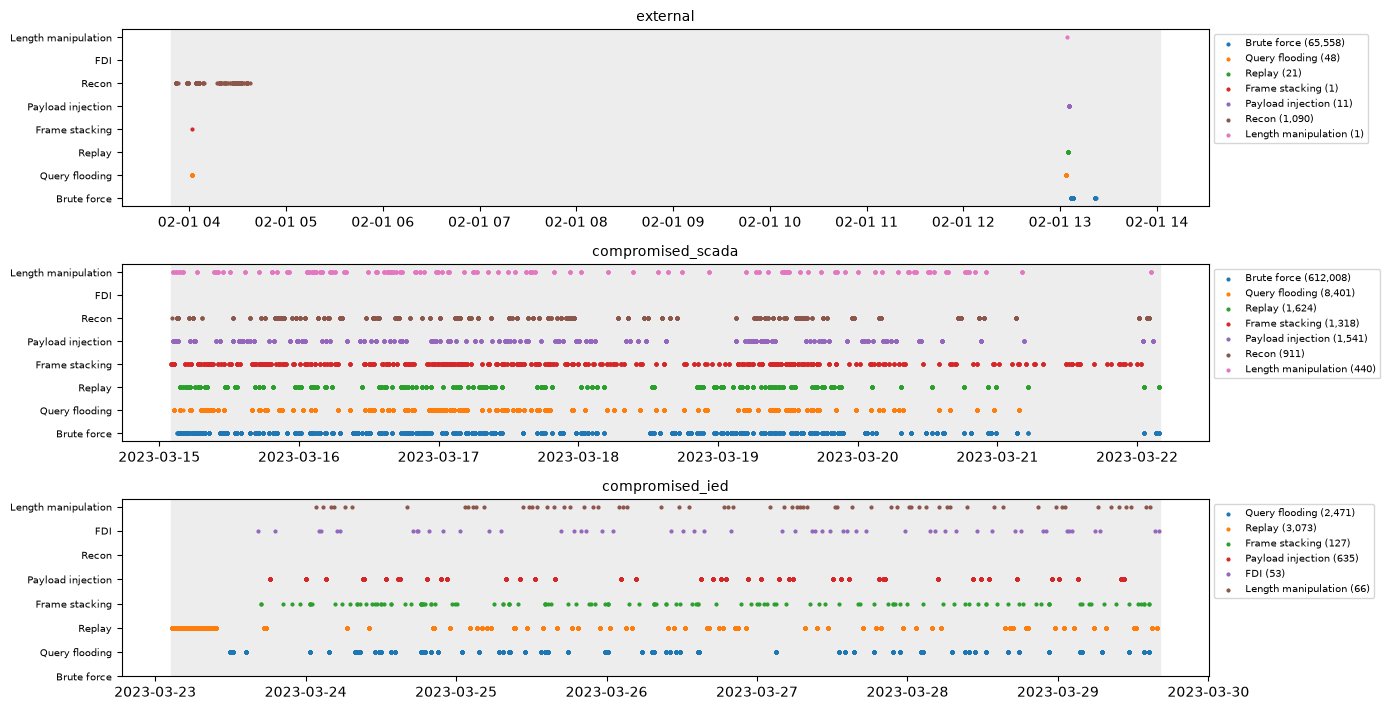

In [14]:
att = P[P.label_id > 0]
fig, axes = plt.subplots(len(ATTACK_SCENARIOS), 1, figsize=(14, 2.4 * len(ATTACK_SCENARIOS)), squeeze=False)
for ax, scen in zip(axes[:, 0], ATTACK_SCENARIOS):
    a = att[att.scenario == scen]
    allp = P[P.scenario == scen]
    if len(allp):
        ax.axvspan(pd.to_datetime(allp.time.min(), unit='s'), pd.to_datetime(allp.time.max(), unit='s'), color='0.93')
    for cls in CLASSES[1:]:
        x = a[a.label == cls]
        if len(x):
            ax.scatter(pd.to_datetime(x.time, unit='s'), np.full(len(x), CLASS_ID[cls]), s=4, label=f'{cls} ({len(x):,})')
    ax.set_yticks(range(1, len(CLASSES))); ax.set_yticklabels(CLASSES[1:], fontsize=7)
    ax.set_title(scen, fontsize=10); ax.legend(fontsize=7, loc='upper left', bbox_to_anchor=(1.0, 1.0))
plt.tight_layout(); plt.show()

Lưu dữ liệu đã gán nhãn

In [15]:
out_root = WORK_DIR / 'labeled'
lab_by_file = {fid: g.sort_values('row') for fid, g in
               P[['file_id', 'row', 'label_id', 'in_delay_window']].groupby('file_id', observed=True)}
for r in tqdm(manifest.itertuples(), total=len(manifest), desc='Ghi parquet'):
    if r.file_id not in lab_by_file:
        continue
    full = pd.read_parquet(WORK_DIR / 'extracted' / r.scenario / (Path(r.file).stem + '.parquet'))
    g = lab_by_file[r.file_id]
    assert len(g) == len(full)
    full['scenario'] = r.scenario
    full['file_id'] = r.file_id
    full['label_id'] = g.label_id.to_numpy()
    full['label'] = pd.Categorical.from_codes(full.label_id.to_numpy(), CLASSES)
    full['in_delay_window'] = g.in_delay_window.to_numpy()
    (out_root / r.scenario).mkdir(parents=True, exist_ok=True)
    full.to_parquet(out_root / r.scenario / (Path(r.file).stem + '.parquet'), index=False)

params = dict(PAD_BEFORE_S=PAD_BEFORE_S, PAD_AFTER_S=PAD_AFTER_S, MERGE_GAP_S=MERGE_GAP_S,
              UNCLOSED_DEFAULT_S=UNCLOSED_DEFAULT_S, REQUIRE_TARGET_IP=REQUIRE_TARGET_IP,
              APPLY_FINE_OFFSET=APPLY_FINE_OFFSET)
(WORK_DIR / 'class_map.json').write_text(json.dumps({'classes': CLASSES, 'labelling_params': params},
                                                    indent=2, ensure_ascii=False), encoding='utf-8')
print('Đã lưu vào', out_root)

Ghi parquet:   0%|          | 0/58 [00:00<?, ?it/s]

Đã lưu vào C:\Users\cvson\Documents\Project\Anomaly-detection-in-ICS\ics-ai\Modbus-Work\labeled
